In [14]:
#| echo: false
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


rng = np.random.default_rng(19)

# The Poisson Process

Car crashes at a busy intersection occur at *random times*. What is a good model for

- **when** crashes happen, and
- **how many** crashes happen in a given window of time?

. . .

::: {.callout-tip}
## Reasonable modeling assumptions

- Crashes are equally likely at any moment (no rush hour, in this simple model).
- What happens in one window of time tells us nothing about a disjoint window.
- In a very short window, we see at most one crash.

:::

. . .

This is the **Bernoulli process** with time chopped into many tiny slots.

. . .

But, how tiny do slots need to be so that in reality each window has at most one crash?  Here, a continuous model would be more natural!

## Poisson process: definition

Define $P(k,\tau) = P(\text{there are exactly } k \text{ arrivals during an interval of length } \tau).$

::: {.callout-note}
## Definition

An arrival process is called a **Poisson process** with **arrival rate** $\lambda>0$ (arrivals per unit time) if it satisfies:

1. **Time homogeneity:** probability $P(k,\tau)$ of $k$ arrivals is the same for every interval of length $\tau$.
2. **Independence:** the numbers of arrivals during a particular interval is independent of the history of arrivals outside of this interval.
3. **Small interval probabilities:** the probabilities satisfy $$P(0, \tau)=1 - \lambda \tau + o_{0}(\tau),\qquad P(1, \tau)= \lambda \tau + o_{1}(\tau),\qquad P(k \ge 2, \tau) = o_{k}(\tau) $$ where $o_i(\tau)$ is a function of $\tau$ that satisfies $\lim_{\tau \rightarrow 0} \frac{o_i(\tau)}{\tau} = 0$.  
:::

. . .

$\lambda\tau$ plays the role of the Bernoulli success probability $p$ in a tiny slot, and since $o_i(\tau)$ is negligible compared to $\tau$, the probabiity of seeing two or more arrivals in a single window is negligible as $\tau$ becomes small.

## Number of Arrivals in an Interval

::: {.callout-note}
## Derivation

Chop $[0,\tau]$ into $n=\tau/\delta$ slots. Each slot is an independent Bernoulli trial with success probability
$$p=\lambda\delta=\frac{\lambda\tau}{n},$$
so the number of arrivals in $[0,\tau]$, $N_\tau\sim\text{Binomial}(n,p)$.
:::

. . .

Let $n\to\infty$ with $np=\lambda\tau$ fixed:

$$\binom{n}{k}p^k(1-p)^{n-k}\;\longrightarrow\;\frac{(\lambda\tau)^k}{k!}e^{-\lambda\tau}.$$

. . .

$N_\tau \rightarrow \text{Poisson}(\lambda \tau)$!

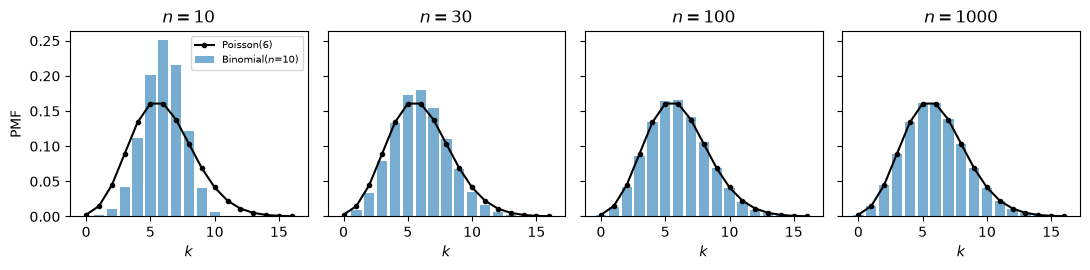

In [15]:
#| fig-height: 3.4
mu = 6.0      # lambda * tau
k = np.arange(0, 17)
fig, axs = plt.subplots(1, 4, figsize=(11, 2.8), sharey=True)
for ax, n in zip(axs, [10, 30, 100, 1000]):
    ax.bar(k, stats.binom.pmf(k, n, mu / n), color="C0", alpha=0.6, label=f"Binomial($n$={n})")
    ax.plot(k, stats.poisson.pmf(k, mu), "ko-", ms=3, label="Poisson(6)")
    ax.set_title(f"$n={n}$"); ax.set_xlabel("$k$")
axs[0].set_ylabel("PMF"); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

---

::: {.callout-note}
## Poisson PMF for the number of arrivals in time $\tau$

$$P(N_\tau=k)=P(k,\tau)=\frac{(\lambda\tau)^k e^{-\lambda\tau}}{k!},\qquad k=0,1,2,\ldots$$
:::

. . .

The mean and variance are $$E[N_\tau]=\lambda\tau,\qquad \text{Var}(N_\tau)=\lambda\tau.$$
These match the Binomial values $np=\lambda\tau$ and $np(1-p)\to\lambda\tau$ in the limit $p\to0$.

## Time of the First Arrival

::: {.callout-note}
## Tail probability

Let $T$ be the time of the first arrival. No arrival by time $t$ means zero arrivals in $[0,t]$:
$$P(T>t)=P(0,t)=e^{-\lambda t},\qquad t\ge0.$$
:::

. . .

Now, we recover the PDF from the CDF: 
$$F_{T}(t)=1-e^{-\lambda t}\quad\Longrightarrow\quad f_{T}(t)=\frac{d}{dt}F_{T}(t)=\lambda e^{-\lambda t},\quad t\ge0.$$


. . .

::: {.callout-tip}
## Conclusion

$T\sim\text{Exponential}(\lambda)$, with
$$E[T]=\frac1\lambda,\qquad\text{Var}(T)=\frac1{\lambda^2}.$$
:::

# Summary: Bernoulli vs. Poisson

## Two descriptions of arrivals

| | **Bernoulli process** | **Poisson process** |
|---|---|---|
| Times of arrival | discrete: $i=1,2,\ldots$ | continuous: $t\ge0$ |
| Arrival rate | $p$ per trial | $\lambda$ per unit time |
| PMF of # of arrivals | Binomial$(n,p)$ | Poisson$(\lambda\tau)$ |
| Interarrival time | Geometric$(p)$ | Exponential$(\lambda)$ |
| Mean interarrival time | $1/p$ | $1/\lambda$ |
| Time of $k$th arrival | Pascal$(k,p)$ | Erlang$(k,\lambda)$ |

. . .

::: {.callout-tip}
## Take-away

Poisson is the continuous-time limit of Bernoulli: **Binomial $\to$ Poisson** and **Geometric $\to$ Exponential**.
:::

### Example: emails

::: {.callout-warning}
## Example

Emails arrive as a Poisson process with rate $\lambda=5$ per hour.

(a) What is the probability of no emails in the next 30 minutes?

(b) What is the probability of exactly 3 emails in the next hour?

(c) What is the expected wait until the next email?
:::

. . .

::: {.callout-note}
## Solution

(a) $\lambda\tau=5(0.5)=2.5$, so $P(N=0)=e^{-2.5}\approx0.082$.

(b) $\lambda\tau=5$, so $P(N=3)=\dfrac{5^3e^{-5}}{3!}\approx0.140$.

(c) $E[T]=1/\lambda=1/5$ hour $=12$ minutes.
:::

## Independence and Memorylessness

- *Independence*: For any time $t$, the history of the process after time $t$ is also a Poisson process with the same rate $\lambda$, and is **independent of the history of the process until time $t$**.
- *Memorylessness*: Let $t$ be a given time and let $\bar{T}$ be the time of the first arrial after time $t$.  Then $\bar{T} - t$ has an exponential distribution with parameter $\lambda$, and is **independent of the history of the process until time $t$**.  $$P(\bar{T} - t > s) = P(0 \text{ arrivals during } [t, t+s]) = P(0,s)$$ 




## Interarrival Times

::: {.callout-note}
## Definition

Let $Y_k$ be the time of the $k$th arrival, with $Y_0=0$. The **interarrival times** are
$$T_1 = Y_1, \qquad T_k=Y_k-Y_{k-1},\qquad k=2,3,\ldots$$
which represent the amount of time between the $(k-1)$st and the $k$th arrivals.  
:::

. . .

Note then that $$Y_k = T_1 + T_2 + \cdots + T_k.$$

## Alternative Description

::: {.callout-tip}
## Alternative description of the Poisson process

- Start with a sequence of independent exponential random variables, $T_1,T_2,\ldots$ **i.i.d. Exponential$(\lambda)$**, and let these represent the interarrival times.
- Record an arrival at times $T_1, T_1 + T_2, T_1 + T_2 + T_3, \cdots$
:::

. . .

By the fresh-start property, the process restarts independently after each arrival, so every gap is distributed identically to $T_1$.

## The $k$th arrival time

::: {.callout-note}
## Definition

$$Y_k=T_1+T_2+\cdots+T_k,$$
a sum of $k$ i.i.d.\ Exponential$(\lambda)$ interarrival times.
:::

. . .

The mean and variance are $$\mathbb{E}[Y_k] = \frac{k}{\lambda} \text{ and } \text{Var}(Y_k) = \frac{k}{\lambda^2}.$$

. . .

The PDF of $Y_k$ is 
$$f_{Y_k}(y)=\frac{\lambda^ky^{k-1}e^{-\lambda y}}{(k-1)!},\quad y\ge0,$$
which is known as the **Erlang PDF of order $k$**.


### Example: IRS hotline

::: {.callout-warning}
## Example

You call the IRS hotline and are tolde that you are the 56th person in line.  Callers depart according to a Poisson process with rate $\lambda=2$ per minute.

- How long will you have to wait on average until your service starts?
- What is the probability that you will have to wait for more than 30 minutes?
:::

. . .

::: {.callout-note}
## Solution

- Your waiting time is $Y_{56}$ which has mean $56/\lambda = 28$.
- $P(Y_{56} \ge 30) = \int_{30}^\infty \frac{1^{56} y^{55} e^{-2y}}{55!} dy$
:::

### Exercise

::: {.callout-caution}
## Exercise

Customers arrive at a shop as a Poisson process with rate $\lambda=6$ per hour.

- What is the probability that exactly 3 customers arrive in the next 20 minutes?

- What is the expected time until the 3rd customer arrives?

- No one has arrived in the last 10 minutes. What is the probability that no one arrives in the next 10 minutes?
:::

. . .

::: {.callout-note}
## Solution

- $\lambda\tau=6\cdot\tfrac13=2$, so $P(k,1/3)=\dfrac{2^3e^{-2}}{3!}=4e^{-2}/3\approx0.1804$.

- $E[T_3]=3/6=0.5$ hours.

- By memorylessness, $e^{-6\cdot(1/6)}=e^{-1}\approx0.368$; the past 10 minutes are irrelevant.
:::

## Splitting

Suppose each arrival of a Poisson$(\lambda)$ process is independently kept with probability $p$ and discarded with probability $1-p$.

. . .

::: {.callout-tip}
## Split Poisson Process

The set of kept arrivals and discarded arrivals are **independent Poisson processes** with rates
$$\lambda_k=p\lambda,\qquad\lambda_d=(1-p)\lambda.$$
:::


## Merging

We can also combine two **independent** Poisson processes with rates $\lambda_1$ and $\lambda_2$ into a single stream by recording an arrival whenever an arrival occurs in either process.

. . .

::: {.callout-tip}
## Result

The merged process is Poisson with rate $\lambda_1+\lambda_2$, and each arrival independently comes from process 1 and process 2 with probabilities $$\frac{\lambda_1}{\lambda_1+\lambda_2} \quad\text{ and }\quad \frac{\lambda_2}{\lambda_1+\lambda_2}$$ respectively, independent of all other arrivals and origins.
:::


### Example: mail packages at the post office

::: {.callout-warning}
## Example

Packages are mailed as a Poisson process with rate 10 per hour. Each package is domestic with probability 0.7 and international with probability 0.3, independently.

(a) What is the probability of no international packages in 30 minutes?

(b) Given that 4 packages arrived in an hour, what is the probability that exactly 1 is international?
:::

. . .

::: {.callout-note}
## Solution

By splitting, domestic packages are Poisson with rate 7 per hour and international packages are Poisson with rate 3 per hour, independent of each other.

(a) $e^{-3(0.5)}=e^{-1.5}\approx0.223$.

(b) Each of the 4 packages is international independently with probability 0.3, so
$\binom41(0.3)(0.7)^3\approx0.412$.
:::

## Sums of a Random Number of RVs


::: {.callout-note}
## Setup

Let $Y=X_1+\cdots+X_N$, where $N$ is a nonnegative integer-valued random variable and the $X_i$ are i.i.d. and independent of $N$.
:::

. . .

::: {.callout-tip}
## Summary

| | Formula |
|---|---|
| Mean | $E[Y]=E[N]\,E[X]$ |
| Variance | $\text{Var}(Y)=E[N]\,\text{Var}(X)+(E[X])^2\,\text{Var}(N)$ |
| Transform | $M_Y(s)=M_N\!\left(\ln M_X(s)\right)$ |
:::

. . .

::: {.callout-warning}
## Where it comes from

Condition on $N$: $E[Y\mid N]=N\,E[X]$ and $\text{Var}(Y\mid N)=N\,\text{Var}(X)$, then apply the law of iterated expectation and the law of total variance from Lecture 10.
:::

## Random Incidence Paradox

::: {.callout-warning}
## Example

Buses arrive as a Poisson process with rate $\lambda$, so the average gap between buses is $1/\lambda$. You arrive at a random time. How long is the gap you land in?
:::

. . .

::: {.callout-note}
## Looking forward and backward

- Time until the next bus: Exponential$(\lambda)$ with mean $1/\lambda$ (fresh start).
- Time since the last bus: also Exponential$(\lambda)$ with mean $1/\lambda$ (run the process backward in time).
:::

. . .

::: {.callout-caution}
## The paradox

The gap containing your arrival has mean about $2/\lambda$, **twice** the average gap.
:::

. . .

::: {.callout-tip}
## Resolution

Random times are more likely to land in **long** gaps. This is length-biased sampling, so the gap you observe is not a typical one.
:::

### Example

::: {.callout-warning}
## Example

Gaps between buses are 5 minutes or 15 minutes, each with probability $\tfrac12$, so the average gap is 10 minutes. What is the average gap seen by a random arriver?
:::

. . .

::: {.callout-note}
## Solution

A random arrival lands in a 5-minute gap with probability $\frac{5}{5+15}=0.25$ and in a 15-minute gap with probability $0.75$:
$$E[\text{observed gap}]=0.25(5)+0.75(15)=12.5\text{ minutes}>10.$$
In general, $E[\text{observed gap}]=\dfrac{E[Y^2]}{E[Y]}$, which for Exponential$(\lambda)$ gaps is $\dfrac{2/\lambda^2}{1/\lambda}=\dfrac2\lambda$.
:::